# revert, reflog, worktree

**이 노트북에서 할 일**

1. 03절처럼 임시 폴더에 팀 원격 저장소와 작성자·리뷰어 저장소를 만듭니다.
2. 이미 원격에 올린 잘못된 커밋을 취소 커밋으로 되돌리고, 작업 폴더를 하나 더 열어 급한 수정을 합니다.
3. 명령 `git reset --hard`로 보이지 않게 된 커밋을 참조 기록에서 찾아 되살립니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 모델 호출은 0번이고 비용은 들지 않습니다.
실행 시간은 1분 이내입니다. 03절에서 쓴 Git이 필요합니다.

실습 폴더 `labs/part1/ch03-git-github`에서 `uv sync --locked`로 만든 `.venv`를 커널로 고릅니다.
첫 셀부터 순서대로 실행합니다. GitHub 계정과 네트워크는 쓰지 않습니다.

## 오늘 볼 그림

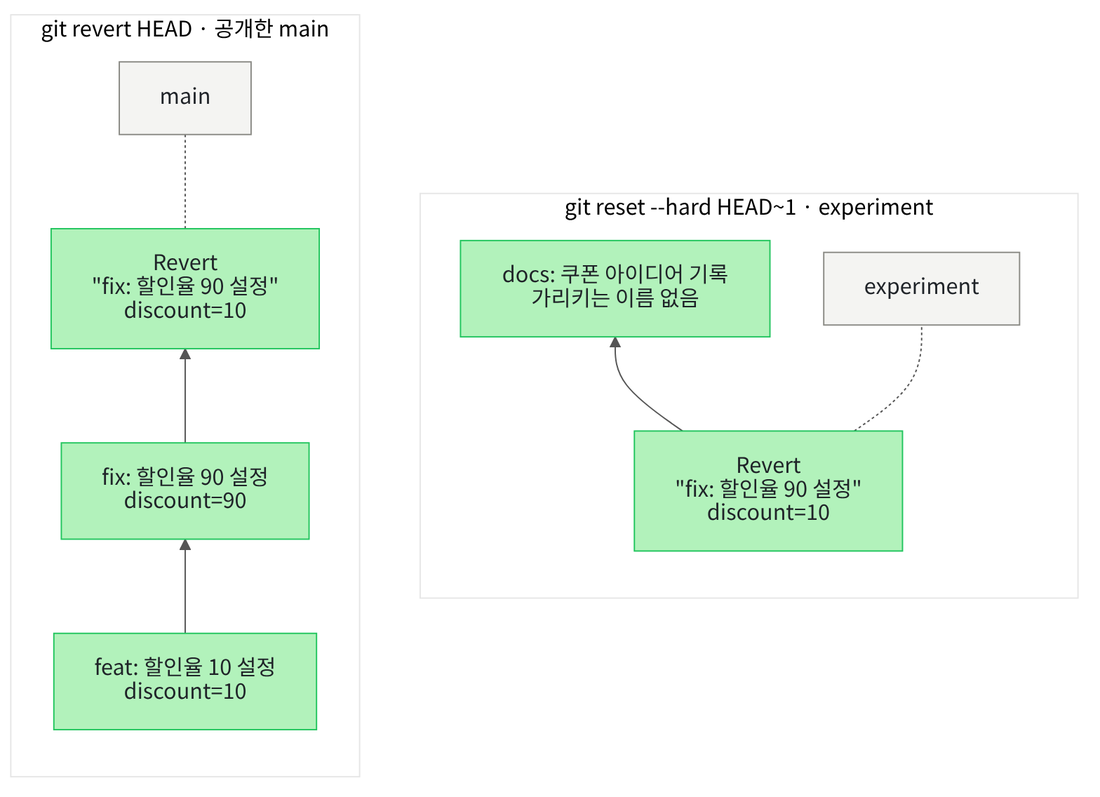

왼쪽 칸이 공개한 main에서 쓴 방법, 오른쪽 칸이 혼자 쓰는 브랜치에서 쓴 방법입니다. 두 칸 모두 아래에서 위로 읽습니다.
왼쪽은 커밋을 하나 더해 취소하므로 잘못된 커밋도 남습니다. 오른쪽은 이름표만 한 커밋 아래로 옮겨, 맨 위 커밋을 가리키는 이름이 없어집니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 03절처럼 빈 임시 폴더를 만들고 그 폴더로 작업 위치를 옮깁니다.
그 안에 원격 저장소 하나와 두 사람의 저장소를 만듭니다. 폴더 이름의 앞머리만 `ch03-04-`로 바꿨습니다.

앞에서 배운 함수는 `git_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 03절처럼 02절 `run_git()`을 가져옵니다.

가져오는 줄은 작업 위치를 옮기기 전에 둡니다. 도구 파일을 현재 작업 폴더에서 찾기 때문입니다.

In [1]:
# 02절 run_git()을 도구 파일에서 가져오고, 저장소와 작업 폴더를 담을 빈 임시 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# 작업 위치를 옮기기 전에 가져옵니다. 도구 파일은 노트북과 같은 폴더에 있습니다
from git_tools import run_git

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch03-04-")
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.

## 2. 가져온 git 명령 함수

1번 준비 셀에서 가져온 `run_git()`은 02절에서 만든 함수입니다. 두 번째 매개변수 `folder`는 명령을 실행할 폴더이고, 기본값 `"."`은 현재 작업 폴더입니다.

이 함수에는 `check=True` 인자가 없습니다. 그래서 git 명령이 실패해도 셀은 멈추지 않고 `종료 코드: 128` 같은 줄을 보여 줍니다.

## 3. 팀 원격 저장소와 작성자의 첫 커밋

03절과 같은 순서로 준비합니다. 원격 저장소 `team.git`을 bare 저장소로 만들고, 작성자가 `author` 폴더로 복제합니다.
작성자 정보도 03절과 같은 `Ch3 Student`를 이 저장소에만 적습니다.

실행 전에 예상합니다. 빈 저장소를 복제했다는 경고가 한 번 나오고, 종료 코드 줄은 없을 것입니다.

In [2]:
# 팀 원격 저장소를 만들고, 작성자가 복제한 저장소에 이름과 전자우편 주소를 적습니다
run_git("init --bare -b main team.git")
run_git("clone team.git author")
run_git('config user.name "Ch3 Student"', "author")
run_git("config user.email student@example.com", "author")

. $ git init --bare -b main team.git
Initialized empty Git repository in [사용자 폴더]/tmp/ch03-04-knwtbftj/team.git/

. $ git clone team.git author
Cloning into 'author'...
done.

author $ git config user.name "Ch3 Student"

author $ git config user.email student@example.com



**결과 읽기** — 줄 `Initialized empty Git repository`로 원격 저장소가 생긴 것을 확인합니다.
경고 `You appear to have cloned an empty repository`는 03절에서 본 것과 같은 안내입니다.
종료 코드 줄이 없으므로 네 명령 모두 성공했습니다.

작성자가 설정 파일 `config.txt`를 만들어 main의 첫 커밋으로 올립니다. 파일에는 할인율 한 줄 `discount=10`만 적습니다.
숫자 10은 10%를 뜻합니다. Ch 2 04절에서 결제 금액을 계산할 때 쓴 할인율 0.1과 같은 값입니다.

실행 전에 예상합니다. 03절처럼 첫 커밋 표시와 새 브랜치 표시가 나올 것입니다.

In [3]:
# 작성자가 할인율 설정 파일을 만들어 첫 커밋으로 기록하고 원격에 올립니다
with open("author/config.txt", "w", encoding="utf-8") as file:
    file.write("discount=10\n")
run_git("add config.txt", "author")
run_git('commit -m "feat: 할인율 10 설정"', "author")
run_git("push -u origin main", "author")

author $ git add config.txt

author $ git commit -m "feat: 할인율 10 설정"
[main (root-commit) ecd00a9] feat: 할인율 10 설정
 1 file changed, 1 insertion(+)
 create mode 100644 config.txt

author $ git push -u origin main
Branch 'main' set up to track remote branch 'main' from 'origin'.
To [사용자 폴더]/tmp/ch03-04-knwtbftj/team.git
 * [new branch]      main -> main



**결과 읽기** — 표시 `main (root-commit)`은 main 브랜치의 첫 커밋이라는 뜻입니다.
올리기 출력의 `[new branch]`로 원격 저장소에도 main이 생긴 것을 확인합니다.

리뷰어도 원격 저장소를 복제합니다. 폴더 이름과 작성자 정보는 03절과 같은 `reviewer`와 `Ch3 Reviewer`입니다.

실행 전에 예상합니다. 원격에 커밋이 있으니 빈 저장소 경고 없이 복제될 것입니다.

In [4]:
# 리뷰어가 원격 저장소를 복제하고, 리뷰어 저장소에만 이름과 전자우편 주소를 적습니다
run_git("clone team.git reviewer")
run_git('config user.name "Ch3 Reviewer"', "reviewer")
run_git("config user.email reviewer@example.com", "reviewer")

. $ git clone team.git reviewer
Cloning into 'reviewer'...
done.

reviewer $ git config user.name "Ch3 Reviewer"

reviewer $ git config user.email reviewer@example.com



**결과 읽기** — 복제 출력은 `Cloning into 'reviewer'...`와 `done.`뿐이고 경고가 없습니다.
이제 두 사람의 main은 같은 첫 커밋에서 출발합니다.

## 4. 잘못된 할인율을 원격에 올리기

작성자가 설정을 고치다가 할인율을 90으로 적었습니다. 90% 할인은 상품을 원래 값의 10%에 파는 셈이라 잘못된 값입니다.
작성자는 실수를 알아채지 못한 채 `fix: 할인율 90 설정`으로 커밋하고 원격에 올립니다.

실행 전에 예상합니다. 원격에 작성자가 모르는 커밋이 없으므로 거절 없이 올라갈 것입니다.

In [5]:
# 작성자가 할인율을 잘못된 값 90으로 바꿔 커밋하고 원격에 올립니다
with open("author/config.txt", "w", encoding="utf-8") as file:
    file.write("discount=90\n")
run_git("add config.txt", "author")
run_git('commit -m "fix: 할인율 90 설정"', "author")
run_git("push", "author")

author $ git add config.txt

author $ git commit -m "fix: 할인율 90 설정"
[main 0c2d754] fix: 할인율 90 설정
 1 file changed, 1 insertion(+), 1 deletion(-)

author $ git push
To [사용자 폴더]/tmp/ch03-04-knwtbftj/team.git
   ecd00a9..0c2d754  main -> main



**결과 읽기** — 커밋 요약 줄 `1 file changed, 1 insertion(+), 1 deletion(-)`은 한 줄을 고쳤다는 뜻입니다.
올리기 출력의 `main -> main`으로 원격 main이 이 커밋으로 옮겨 갔습니다.

리뷰어가 `git pull`로 원격의 새 커밋을 받고, 받은 설정 파일을 읽습니다.
이렇게 원격에 올려 다른 사람이 받은 커밋을 이 절에서는 공개한 커밋이라고 부릅니다.

실행 전에 예상합니다. 03절처럼 fast-forward 병합으로 받고, 파일에는 90이 보일 것입니다.

In [6]:
# 리뷰어가 원격 main을 받아 오고, 받은 설정 파일을 읽습니다
run_git("pull", "reviewer")
with open("reviewer/config.txt", "r", encoding="utf-8") as file:
    config_text = file.read()
print("리뷰어의 config.txt:", config_text)

reviewer $ git pull
Updating ecd00a9..0c2d754
Fast-forward
 config.txt | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
From [사용자 폴더]/tmp/ch03-04-knwtbftj/team
   ecd00a9..0c2d754  main       -> origin/main

리뷰어의 config.txt: discount=90



**결과 읽기** — 줄 `Fast-forward`로 리뷰어의 main이 새 커밋으로 옮겨 갔습니다.
마지막 줄 `리뷰어의 config.txt: discount=90`으로 잘못된 값이 리뷰어 폴더에도 들어온 것을 확인합니다.

이제 이 커밋은 작성자 혼자의 것이 아닙니다. 원격과 리뷰어 저장소에도 같은 커밋이 있습니다.

## 5. git revert로 취소 커밋 더하기

작성자가 이 커밋을 이력에서 빼고 올리면, 원격에는 작성자 저장소에 없는 커밋이 남습니다. 03절에서 본 것처럼 원격은 이런 올리기를 거절합니다.
억지로 덮어 올리는 옵션 `--force`는 리뷰어가 이미 받은 커밋과 이력이 어긋나게 만듭니다. 이 두 경우는 이번에 실행하지 않았습니다.

명령 `git revert`는 지정한 커밋의 변경을 거꾸로 적용한 새 커밋을 만듭니다. 대상 `HEAD`는 01절에서 배운 지금 기준인 마지막 커밋입니다.
옵션 `--no-edit`는 메시지 편집기를 열지 않고 git이 정한 메시지를 그대로 씁니다.

실행 전에 예상합니다. 이력에 커밋이 하나 더 생기고, 잘못된 커밋도 그대로 남을 것입니다.

In [7]:
# 마지막 커밋의 변경을 거꾸로 적용한 새 커밋을 만들고, 이력과 파일을 확인합니다
run_git("revert --no-edit HEAD", "author")
run_git("log --oneline", "author")
with open("author/config.txt", "r", encoding="utf-8") as file:
    config_text = file.read()
print("작성자의 config.txt:", config_text)

author $ git revert --no-edit HEAD
[main ff8bc1c] Revert "fix: 할인율 90 설정"
 Date: Mon Sep 21 10:18:57 2026 +0000
 1 file changed, 1 insertion(+), 1 deletion(-)

author $ git log --oneline
ff8bc1c Revert "fix: 할인율 90 설정"
0c2d754 fix: 할인율 90 설정
ecd00a9 feat: 할인율 10 설정

작성자의 config.txt: discount=10



**결과 읽기** — 새 커밋의 메시지는 `Revert "fix: 할인율 90 설정"`입니다. 줄 `Date:`에는 이 커밋을 만든 시각이 나옵니다.
이력은 커밋 세 개이고, 잘못된 커밋 `fix: 할인율 90 설정`도 가운데에 그대로 있습니다.
마지막 줄은 `작성자의 config.txt: discount=10`입니다.

파일은 첫 커밋과 같아졌지만 이력은 뒤로 가지 않았습니다. 「90으로 바꿈」과 「그 변경을 취소함」이 둘 다 기록에 남습니다.

취소 커밋을 원격에 올리고, 리뷰어가 받습니다. 파일은 앞에서와 같은 방법으로 읽습니다.

실행 전에 예상합니다. 새 커밋을 더했을 뿐이므로 올리기는 거절되지 않고, 리뷰어는 fast-forward 병합으로 받을 것입니다.

In [8]:
# 취소 커밋을 원격에 올리고, 리뷰어가 받아 설정 파일을 다시 읽습니다
run_git("push", "author")
run_git("pull", "reviewer")
with open("reviewer/config.txt", "r", encoding="utf-8") as file:
    config_text = file.read()
print("리뷰어의 config.txt:", config_text)

author $ git push
To [사용자 폴더]/tmp/ch03-04-knwtbftj/team.git
   0c2d754..ff8bc1c  main -> main

reviewer $ git pull
Updating 0c2d754..ff8bc1c
Fast-forward
 config.txt | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
From [사용자 폴더]/tmp/ch03-04-knwtbftj/team
   0c2d754..ff8bc1c  main       -> origin/main

리뷰어의 config.txt: discount=10



**결과 읽기** — 올리기 출력은 `main -> main`이고, 거절 표시와 종료 코드 줄이 없습니다.
리뷰어 쪽은 `Fast-forward`로 받았고, 마지막 줄은 `리뷰어의 config.txt: discount=10`입니다.

리뷰어는 따로 할 일이 없었습니다. 평소처럼 받기만 해도 할인율이 10으로 돌아왔습니다.

## 6. git worktree로 작업 폴더 하나 더 열기

작성자는 기본 폴더 `author`에서 할인 행사 공지 초안 `notice.txt`를 쓰는 중입니다. 아직 커밋하지 않은 파일입니다.
이때 할인율에 상한을 두는 급한 수정을 부탁받았습니다.

명령 `git worktree add`는 같은 저장소에 작업 폴더를 하나 더 만듭니다. 옵션 `-b fix/urgent`는 새 브랜치를 만듭니다.
마지막 `../urgent-fix`는 새 폴더 경로입니다. 앞의 `..`은 한 칸 위 폴더라서 새 폴더는 `author` 옆에 생깁니다.
명령 `git worktree list`는 이 저장소에 연결된 작업 폴더 목록을 보여 줍니다.

실행 전에 예상합니다. 목록에 폴더가 두 줄 나오고, 두 줄의 브랜치가 서로 다를 것입니다.

In [9]:
# 기본 폴더에 커밋하지 않은 공지 초안을 둔 채, 급한 수정용 작업 폴더를 하나 더 엽니다
with open("author/notice.txt", "w", encoding="utf-8") as file:
    file.write("공지 초안: 할인 행사 안내\n")
# 새 브랜치 fix/urgent를 만들어 author 옆 urgent-fix 폴더에 꺼내 놓습니다
run_git("worktree add -b fix/urgent ../urgent-fix", "author")
run_git("worktree list", "author")

author $ git worktree add -b fix/urgent ../urgent-fix
Preparing worktree (new branch 'fix/urgent')
HEAD is now at ff8bc1c Revert "fix: 할인율 90 설정"

author $ git worktree list
[사용자 폴더]/tmp/ch03-04-knwtbftj/author      ff8bc1c [main]
[사용자 폴더]/tmp/ch03-04-knwtbftj/urgent-fix  ff8bc1c [fix/urgent]



**결과 읽기** — 줄 `Preparing worktree (new branch 'fix/urgent')`는 새 브랜치로 새 폴더를 준비했다는 뜻입니다.
목록은 두 줄입니다. 첫 줄 끝은 `[main]`, 둘째 줄 끝은 `[fix/urgent]`입니다.

앞쪽 경로는 실행할 때마다 달라지는 임시 폴더라 읽지 않습니다. 경로 앞 `[사용자 폴더]`는 실행 도구가 사용자 폴더 이름을 가린 표시입니다.
가운데 글자는 커밋 해시이고 두 줄이 같습니다.
두 폴더가 같은 커밋에서 출발했다는 뜻입니다.

새 폴더 `urgent-fix`에서 급한 수정을 커밋합니다. 설정 파일에 할인율 상한 줄 `max_discount=30`을 더합니다.
함수 `run_git()`의 두 번째 인자에 새 폴더 이름을 넣으면 그 폴더에서 명령이 실행됩니다.

실행 전에 예상합니다. 커밋 출력의 대괄호 안에 main이 아니라 새 브랜치 이름이 보일 것입니다.

In [10]:
# 새 작업 폴더에서 설정 파일에 할인율 상한을 더해 커밋하고, 브랜치 목록을 봅니다
urgent_config = """discount=10
max_discount=30
"""
with open("urgent-fix/config.txt", "w", encoding="utf-8") as file:
    file.write(urgent_config)
run_git("add config.txt", "urgent-fix")
run_git('commit -m "fix: 할인율 상한 30 추가"', "urgent-fix")
run_git("branch", "urgent-fix")

urgent-fix $ git add config.txt

urgent-fix $ git commit -m "fix: 할인율 상한 30 추가"
[fix/urgent 4ab70b4] fix: 할인율 상한 30 추가
 1 file changed, 1 insertion(+)

urgent-fix $ git branch
* fix/urgent
+ main



**결과 읽기** — 커밋 출력은 `[fix/urgent`로 시작하고, 요약 줄은 `1 file changed, 1 insertion(+)`입니다.
브랜치 목록의 `* fix/urgent`는 이 폴더가 지금 쓰는 브랜치입니다.
목록의 `+ main`에서 더하기 표시는 다른 작업 폴더가 쓰는 브랜치라는 뜻입니다.

기본 폴더 `author`의 상태와 브랜치 목록을 봅니다. 설정 파일도 읽어 급한 수정이 이 폴더에 들어왔는지 확인합니다.

실행 전에 예상합니다. 공지 초안은 추적하지 않는 파일로 그대로 있고, 설정 파일은 한 줄일 것입니다.

In [11]:
# 기본 폴더의 상태와 브랜치 목록을 보고, 설정 파일을 읽습니다
run_git("status --short", "author")
run_git("branch", "author")
with open("author/config.txt", "r", encoding="utf-8") as file:
    config_text = file.read()
print("작성자의 config.txt:", config_text)

author $ git status --short
?? notice.txt

author $ git branch
+ fix/urgent
* main

작성자의 config.txt: discount=10



**결과 읽기** — 상태 표시 `?? notice.txt`로 공지 초안이 그대로 남아 있습니다. 브랜치 목록은 `+ fix/urgent`와 `* main`입니다.
마지막 줄은 `작성자의 config.txt: discount=10`이고, 상한 줄이 없습니다.

두 폴더는 커밋과 브랜치 기록을 함께 쓰지만 작업 파일은 따로 가집니다.
그래서 공지 초안을 커밋하거나 치우지 않고도 다른 브랜치에서 커밋할 수 있었습니다.

## 7. 값 하나 바꿔 보기 — 이미 쓰는 브랜치로 폴더 열기

6번에서는 새 브랜치 `fix/urgent`로 작업 폴더를 열었습니다. 이번에는 브랜치만 바꿔, 기본 폴더가 쓰는 `main`으로 폴더를 엽니다.
옵션 `-b`는 새 브랜치를 만들 때 적으므로 뺍니다. 새 폴더 경로는 `../main-copy`로 둡니다.

실행 전에 예상합니다. 기본 폴더가 main을 이미 쓰고 있으니 거절되고, 목록은 그대로 두 줄일 것입니다.

In [12]:
# 기본 폴더가 이미 쓰는 main 브랜치로 작업 폴더를 하나 더 열어 보고, 목록을 봅니다
run_git("worktree add ../main-copy main", "author")
run_git("worktree list", "author")

author $ git worktree add ../main-copy main
Preparing worktree (checking out 'main')
fatal: 'main' is already checked out at '[사용자 폴더]/tmp/ch03-04-knwtbftj/author'

종료 코드: 128
author $ git worktree list
[사용자 폴더]/tmp/ch03-04-knwtbftj/author      ff8bc1c [main]
[사용자 폴더]/tmp/ch03-04-knwtbftj/urgent-fix  4ab70b4 [fix/urgent]



**결과 읽기** — 줄 `fatal: 'main' is already checked out at`은 main을 이미 다른 작업 폴더에서 쓰고 있다는 뜻입니다.
그 뒤 경로는 기본 폴더 `author`입니다. 줄 `종료 코드: 128`이 나오고, 이어진 목록은 여전히 두 줄입니다.

작업 폴더를 하나 더 열 때는 다른 폴더가 쓰지 않는 브랜치를 고릅니다. 6번처럼 새 브랜치를 만들며 여는 방법이 그 예입니다.

## 8. 추가 작업 폴더 정리하기

급한 수정 커밋은 `fix/urgent` 브랜치에 남았으니 추가 작업 폴더는 이제 필요 없습니다.
명령 `git worktree remove`는 추가 작업 폴더를 지우고 저장소와의 연결도 풉니다.
이 브랜치를 main에 병합하고 올리는 일은 02절 순서와 같아 이번에는 실행하지 않았습니다.

실행 전에 예상합니다. 작업 폴더 목록은 한 줄로 줄고, 브랜치 목록에는 `fix/urgent`가 남을 것입니다.

In [13]:
# 급한 수정용 작업 폴더를 정리하고, 작업 폴더 목록과 브랜치 목록, 파일 목록을 봅니다
run_git("worktree remove ../urgent-fix", "author")
run_git("worktree list", "author")
run_git("branch", "author")
file_names = os.listdir()
print("현재 작업 폴더의 파일:", sorted(file_names))

author $ git worktree remove ../urgent-fix

author $ git worktree list
[사용자 폴더]/tmp/ch03-04-knwtbftj/author  ff8bc1c [main]

author $ git branch
  fix/urgent
* main

현재 작업 폴더의 파일: ['author', 'reviewer', 'team.git']


**결과 읽기** — 작업 폴더 목록은 `[main]`으로 끝나는 한 줄입니다. 브랜치 목록에는 더하기 표시 없는 `fix/urgent`와 `* main`이 있습니다.
현재 작업 폴더의 파일은 `['author', 'reviewer', 'team.git']`이고, `urgent-fix` 폴더는 없습니다.

폴더를 지워도 그 폴더에서 만든 커밋과 브랜치는 저장소에 남습니다.

## 9. Before — reset --hard로 커밋 지우기

작성자가 기본 폴더에서 새 브랜치 `experiment`를 만들고, 쿠폰 아이디어를 `idea.txt`에 적어 커밋합니다.
명령 `git switch -c`는 02절에서 배웠습니다. 이 브랜치는 원격에 올리지 않은 작성자 혼자의 브랜치입니다.

실행 전에 예상합니다. 대괄호 안에 experiment가 보이는 커밋 출력이 나올 것입니다.

In [14]:
# Before: 새 브랜치에서 쿠폰 아이디어 파일을 만들어 커밋합니다
run_git("switch -c experiment", "author")
with open("author/idea.txt", "w", encoding="utf-8") as file:
    file.write("첫 주문 쿠폰 아이디어\n")
run_git("add idea.txt", "author")
run_git('commit -m "docs: 쿠폰 아이디어 기록"', "author")

author $ git switch -c experiment
Switched to a new branch 'experiment'

author $ git add idea.txt

author $ git commit -m "docs: 쿠폰 아이디어 기록"
[experiment 7637e1a] docs: 쿠폰 아이디어 기록
 1 file changed, 1 insertion(+)
 create mode 100644 idea.txt



**결과 읽기** — 줄 `Switched to a new branch 'experiment'`로 새 브랜치로 옮겨 갔습니다.
커밋 출력은 `[experiment`로 시작하고, `create mode 100644 idea.txt`로 새 파일이 기록됐습니다.

작성자는 이 아이디어를 쓰지 않기로 하고, 마지막 커밋을 지우려고 `git reset --hard HEAD~1`을 실행합니다.
명령 `git reset`은 지금 브랜치 이름을 지정한 커밋으로 옮깁니다. 대상 `HEAD~1`은 01절에서 배운 마지막 커밋의 바로 앞 커밋입니다.
옵션 `--hard`는 색인과 작업 폴더의 추적하는 파일까지 그 커밋 상태로 맞춥니다.

실행 전에 예상합니다. 이력에서 아이디어 커밋이 보이지 않고, 폴더에서 `idea.txt`도 사라질 것입니다.

In [15]:
# Before: 브랜치 이름을 한 커밋 앞으로 옮기고, 이력과 폴더의 파일을 확인합니다
run_git("reset --hard HEAD~1", "author")
run_git("log --oneline", "author")
file_names = os.listdir("author")
print("idea.txt가 폴더에 있는가:", "idea.txt" in file_names)

author $ git reset --hard HEAD~1
HEAD is now at ff8bc1c Revert "fix: 할인율 90 설정"

author $ git log --oneline
ff8bc1c Revert "fix: 할인율 90 설정"
0c2d754 fix: 할인율 90 설정
ecd00a9 feat: 할인율 10 설정

idea.txt가 폴더에 있는가: False


**결과 읽기** — 줄 `HEAD is now at` 뒤에는 브랜치가 옮겨 간 커밋 `Revert "fix: 할인율 90 설정"`이 나옵니다.
이력 맨 위도 같은 커밋이고, 쿠폰 아이디어 커밋은 목록에 없습니다. 마지막 줄은 `idea.txt가 폴더에 있는가: False`입니다.

잠시 뒤 작성자에게 이 아이디어가 다시 필요해졌습니다. 이력에도 폴더에도 보이지 않아 커밋이 사라진 것처럼 보입니다.

## 10. After — 참조 기록에서 찾아 브랜치 이름 붙이기

커밋은 저장소에 남아 있지만, 가리키는 이름이 없어 이력 목록에 나오지 않습니다. 그래서 이름이 가리켰던 기록에서 찾습니다.
명령 `git reflog`는 이 저장소에서 HEAD가 옮겨 간 기록을 최근 것부터 보여 줍니다.
이 기록을 참조 기록(reflog)이라고 부릅니다. 옵션 `-5`는 최근 다섯 줄만 보여 달라는 뜻입니다.

실행 전에 예상합니다. 맨 위에 방금 한 reset 줄이 있고, 그 아래에 아이디어 커밋 줄이 있을 것입니다.

In [16]:
# After: HEAD가 옮겨 간 기록을 최근 다섯 줄만 봅니다
run_git("reflog -5", "author")

author $ git reflog -5
ff8bc1c HEAD@{0}: reset: moving to HEAD~1
7637e1a HEAD@{1}: commit: docs: 쿠폰 아이디어 기록
ff8bc1c HEAD@{2}: checkout: moving from main to experiment
ff8bc1c HEAD@{3}: revert: Revert "fix: 할인율 90 설정"
0c2d754 HEAD@{4}: commit: fix: 할인율 90 설정



**결과 읽기** — 맨 위 줄은 `HEAD@{0}: reset: moving to HEAD~1`로, 방금 실행한 reset입니다.
둘째 줄 `HEAD@{1}: commit: docs: 쿠폰 아이디어 기록`이 찾던 커밋입니다. 그 아래로 브랜치 전환, revert, 잘못된 커밋 줄이 이어집니다. 셋째 줄 `checkout`은 커밋은 그대로이고 브랜치만 바꾼 기록입니다.

이름 `HEAD@{1}`은 HEAD가 한 번 전에 가리키던 커밋이라는 뜻입니다. 줄 앞의 해시 대신 이 이름으로 커밋을 가리킬 수 있습니다.

찾은 커밋에 새 브랜치 이름 `recovered-idea`를 붙입니다. 명령 `git branch 이름 커밋`은 지정한 커밋을 가리키는 브랜치를 만듭니다.
지금 브랜치는 옮기지 않습니다. 이름이 생기면 02절의 `git log --oneline -1`과 01절의 `git show 커밋:파일`로 그 커밋을 읽을 수 있습니다.

실행 전에 예상합니다. 새 브랜치의 마지막 커밋이 아이디어 커밋이고, 파일 내용이 보일 것입니다.

In [17]:
# After: 찾은 커밋에 브랜치 이름을 붙이고, 그 커밋의 메시지와 파일 내용을 봅니다
run_git("branch recovered-idea HEAD@{1}", "author")
run_git("log --oneline -1 recovered-idea", "author")
run_git("show recovered-idea:idea.txt", "author")

author $ git branch recovered-idea HEAD@{1}

author $ git log --oneline -1 recovered-idea
7637e1a docs: 쿠폰 아이디어 기록

author $ git show recovered-idea:idea.txt
첫 주문 쿠폰 아이디어



**결과 읽기** — 브랜치를 만든 명령 아래는 비어 있고 종료 코드 줄도 없습니다.
새 브랜치의 마지막 커밋은 `docs: 쿠폰 아이디어 기록`이고, 파일 내용은 `첫 주문 쿠폰 아이디어`입니다.

이제 이 커밋은 이름이 있어 이력 목록에서 다시 찾을 수 있습니다.

마지막으로 새 브랜치로 옮겨 가 작업 폴더에 파일이 돌아왔는지 봅니다. 확인은 Before와 같은 방법으로 합니다.

실행 전에 예상합니다. Before에서 `False`였던 확인이 `True`로 바뀔 것입니다.

In [18]:
# After: 되살린 브랜치로 옮겨 가고, Before와 같은 방법으로 폴더의 파일을 확인합니다
run_git("switch recovered-idea", "author")
file_names = os.listdir("author")
print("idea.txt가 폴더에 있는가:", "idea.txt" in file_names)

author $ git switch recovered-idea
Switched to branch 'recovered-idea'

idea.txt가 폴더에 있는가: True


**결과 읽기** — 줄 `Switched to branch 'recovered-idea'`로 새 브랜치로 옮겨 갔습니다.
마지막 줄은 `idea.txt가 폴더에 있는가: True`입니다. Before에서 본 `False`가 바뀌어, 지웠던 커밋의 파일이 폴더에 돌아왔습니다.

## 정리

- 원격에 올려 다른 사람이 받은 커밋은 `git revert`로 취소 커밋을 더해 되돌렸습니다. 잘못된 커밋과 취소 커밋이 둘 다 이력에 남았고, 리뷰어는 `Fast-forward`로 받았습니다.
- 명령 `git worktree add`로 같은 저장소의 다른 브랜치를 폴더 하나에 따로 열었습니다. 다른 폴더가 이미 쓰는 브랜치는 `종료 코드: 128`로 거절됐습니다.
- 명령 `git reset --hard`로 이름을 옮겨 보이지 않게 된 커밋은 `git reflog`에서 `HEAD@{1}`로 찾아 새 브랜치 이름을 붙였습니다.

이번에는 Linux의 Git 2.34.1로, 임시 폴더의 원격 저장소를 써서 실행했습니다. 기한이 지나 참조 기록이 지워지는 경우와 GitHub 화면은 실행하지 않았습니다.
다음 절에서는 비밀 값이 커밋에 들어간 경우를 다룹니다. 취소 커밋을 더해도 지난 커밋에는 값이 남으므로, 기록 자체를 정리하는 절차를 봅니다.